In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    encoding="latin1",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
print("Available columns:")
print(df.columns.tolist())

required_columns = [
    "Sales",
    "Sales per customer",
    "Order Item Total",
    "Order Item Product Price",
    "Category Name",
    "Order Id",
    "Product Name",
    "Order Item Quantity"
]

for col in required_columns:
    if col in df.columns:
        print(f"{col}: Available")
    else:
        print(f"{col}: Missing")

Available columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'ship

In [4]:
value_columns = [
    "Sales",
    "Order Item Total",
    "Sales per customer",
    "Order Item Product Price"
]

available_columns = [
    col for col in value_columns if col in df.columns
]

for col in available_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

summary = df[available_columns].agg(
    ["count", "sum", "mean", "median", "min", "max"]
).T

summary.columns = [
    "Count", "Total", "Average",
    "Median", "Minimum", "Maximum"
]

display(summary.round(2))

,Count,Total,Average,Median,Minimum,Maximum
Sales,180519.0,36784735.01,203.77,199.92,9.99,1999.99
Order Item Total,180519.0,33054402.38,183.11,163.99,7.49,1939.99
Sales per customer,180519.0,33054402.38,183.11,163.99,7.49,1939.99
Order Item Product Price,180519.0,25495158.68,141.23,59.99,9.99,1999.99


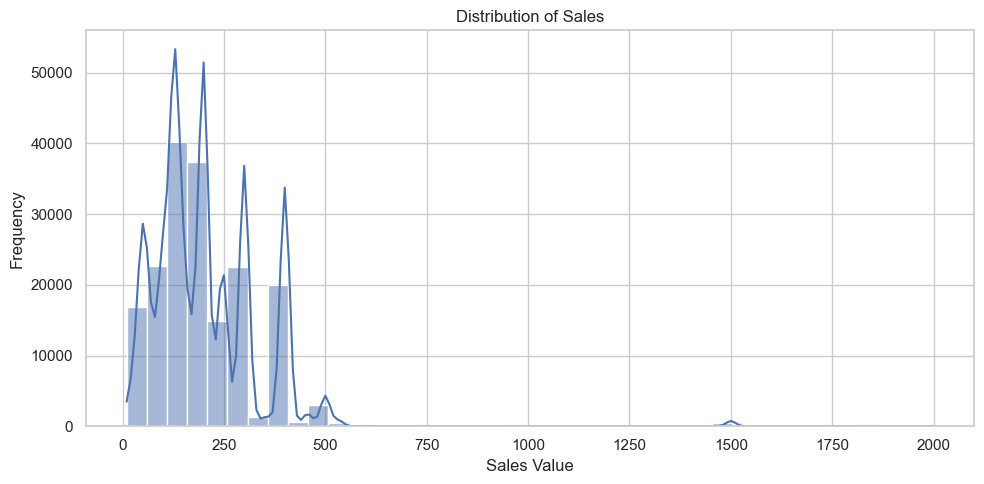

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=40,
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

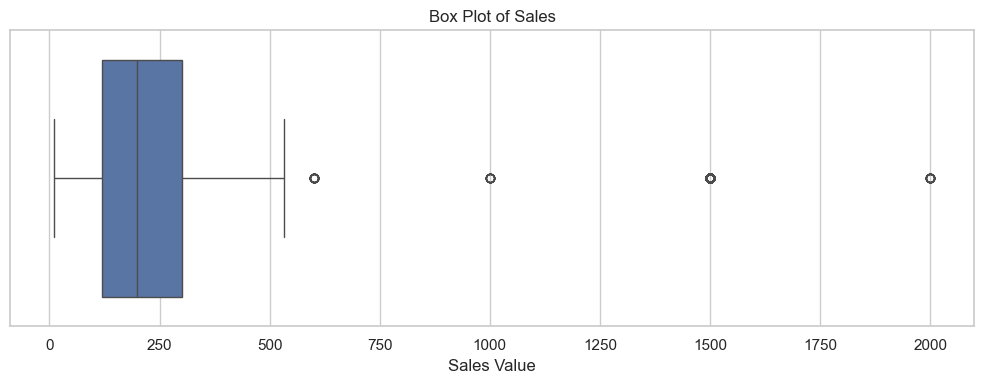

In [6]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Sales"].dropna())

plt.title("Box Plot of Sales")
plt.xlabel("Sales Value")
plt.tight_layout()
plt.show()

In [7]:
sales = df["Sales"].dropna()

Q1 = sales.quantile(0.25)
Q3 = sales.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

unusual_values = df[
    (df["Sales"] < lower_limit) |
    (df["Sales"] > upper_limit)
].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("Potential unusual rows:", len(unusual_values))

display(
    unusual_values[
        ["Order Id", "Product Name", "Category Name", "Sales"]
    ].head(20)
)

Q1: 119.9800034
Q3: 299.9500122
IQR: 179.97000880000002
Lower limit: -149.97500980000007
Upper limit: 569.9050254000001
Potential unusual rows: 488


,Order Id,Product Name,Category Name,Sales
152,70734,Dell Laptop,Computers,1500.00000
155,70769,Dell Laptop,Computers,1500.00000
160,70534,Dell Laptop,Computers,1500.00000
172,70544,Dell Laptop,Computers,1500.00000
174,68879,SOLE E25 Elliptical,Basketball,999.98999
1353,70617,Dell Laptop,Computers,1500.00000
1370,70746,Dell Laptop,Computers,1500.00000
1375,70744,Dell Laptop,Computers,1500.00000
1594,70795,Dell Laptop,Computers,1500.00000
3204,74524,Dell Laptop,Computers,1500.00000


In [9]:
category_summary = (
    df.groupby("Category Name")["Sales"]
      .agg(["count", "sum", "mean", "median", "min", "max"])
      .sort_values("sum", ascending=False)
)

category_summary.columns = [
    "Count",
    "Total Sales",
    "Average Sales",
    "Median Sales",
    "Minimum Sales",
    "Maximum Sales"
]

display(category_summary.round(2))

,Count,Total Sales,Average Sales,Median Sales,Minimum Sales,Maximum Sales
Category Name,,,,,,
Fishing,17325,6929653.69,399.98,399.98,399.98,399.98
Cleats,24551,4431942.78,180.52,179.97,59.99,299.99
Camping & Hiking,13729,4118425.57,299.98,299.98,299.98,299.98
Cardio Equipment,12487,3694843.20,295.90,299.97,30.00,499.95
Women's Apparel,21035,3147800.00,149.65,150.00,50.00,250.00
Water Sports,15540,3113844.68,200.38,199.99,199.99,349.99
Men's Footwear,22246,2891757.66,129.99,129.99,129.99,129.99
Indoor/Outdoor Games,19298,2888993.91,149.70,149.94,49.98,249.90
Shop By Sport,10984,1309522.04,119.22,119.97,30.00,199.99


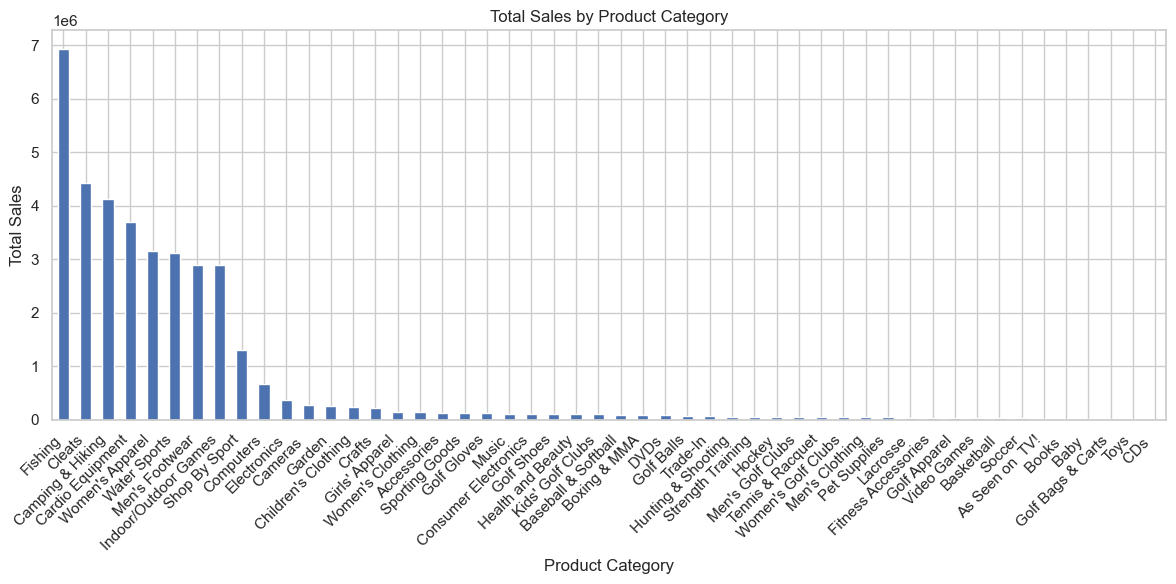

In [10]:
category_summary["Total Sales"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()